<a href="https://colab.research.google.com/github/naik-aarya/Insurance_app/blob/main/Insurance_Premiun_Price_Prediction_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Insurance Premiun Price Prediction**

**data**: https://drive.google.com/file/d/1H0cXqL8H8ikO5ayTWAliIrPbRnbFrkJW/view?usp=sharing


# **Problem Statement**

The goal of this project is to develop a **predictive model** that accurately estimates the **medical insurance costs** for individuals based on various **demographic, lifestyle, and health-related factors**. By applying machine learning techniques, we aim to assist **insurance companies** in better understanding their risk profiles and help individuals gain insights into how different factors influence their **insurance premiums**.

# **Objective**

The objective of this project is to build a **machine learning model** that predicts **medical insurance charges** based on an individual’s demographic, lifestyle, and health-related information such as age, BMI, smoking habits, gender, and region.

- Analyze the factors affecting **insurance costs.**
- **Predict insurance premiums** accurately using machine learning algorithms.
- Help **insurance companies** assess customer risk profiles.
- Provide **individuals with insights** into how personal and health factors impact insurance expenses.

# **Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# **Load data**

In [ ]:
# csv : comma seperated values
# name , age
# John , 30
data = pd.read_csv('insurance_data.csv')
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,NaN,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# **Domain Analysis**
The descriptions of the variables based on the insurance dataset:

1. **Age**
   - **Description:** Age of the primary beneficiary covered by health insurance.
   - **Type:** Continuous numerical variable.

2. **Sex**
   - **Description:** Gender of the insurance contractor.
   - **Type:** Categorical variable with two levels: female, male.

3. **BMI (Body Mass Index)**
   - **Description:** Body mass index, which is a measure of body fat based on height and weight.
   - **Type:** Continuous numerical variable.
   - **Ideal Range:** Ideally between 18.5 to 24.9 kg/m².

4. **Children**
   - **Description:** Number of children covered by health insurance or number of dependents.
   - **Type:** Discrete numerical variable.

5. **Smoker**
   - **Description:** Binary indicator if the beneficiary is a smoker.
   - **Type:** Categorical variable with two levels: yes, no.

6. **Region**
   - **Description:** The beneficiary's residential area in the US.
   - **Type:** Categorical variable with four levels: northeast, southeast, southwest, northwest.

7. **Charges**
   - **Description:** Individual medical costs billed by health insurance.
   - **Type:** Continuous numerical variable.

# **Basic Checks**

In [ ]:
# Shape : find number of rows and columns
data.shape

(1338, 7)

There are **1338 rows** and **7 columns**.

In [ ]:
# head : Used to display first n rows but by default first 5 rows
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,NaN,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# tail : Used to display last n rows but by default gives last 5 rows
data.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [ ]:
# dtypes : Used to find data type of each column
data.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [ ]:
# info : How much memory used by data
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1335 non-null   object 
 2   bmi       1336 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1336 non-null   object 
 5   region    1335 non-null   object 
 6   charges   1335 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
# print all the columns
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [ ]:
# print only the numerical columns
num_data = data.select_dtypes(include=['int64','float64'])
num_data

,age,bmi,children,charges
0,19,27.900,0,16884.92400
1,18,33.770,1,1725.55230
2,28,33.000,3,4449.46200
3,33,22.705,0,21984.47061
4,32,28.880,0,3866.85520
...,...,...,...,...
1333,50,30.970,3,10600.54830
1334,18,31.920,0,2205.98080
1335,18,36.850,0,1629.83350
1336,21,25.800,0,2007.94500


In [ ]:
# print only the categorical/text columns
cat_data = data.select_dtypes(include='object')
cat_data

,sex,smoker,region
0,female,yes,southwest
1,male,no,southeast
2,male,no,southeast
3,male,NaN,northwest
4,male,no,northwest
...,...,...,...
1333,male,no,northwest
1334,female,no,northeast
1335,female,no,southeast
1336,female,no,southwest


In [ ]:
# unique values in categorical columns
for x in cat_data:
  print(x,':',data[x].unique())

sex : ['female' 'male' nan]
smoker : ['yes' 'no' nan]
region : ['southwest' 'southeast' 'northwest' 'northeast' nan]


In [ ]:
# Find value count of each category
for x in cat_data:
  print(data[x].value_counts())
  print()

sex
male      674
female    661
Name: count, dtype: int64

smoker
no     1063
yes     273
Name: count, dtype: int64

region
southeast    363
northwest    325
southwest    324
northeast    323
Name: count, dtype: int64



In [ ]:
# describe : Used to perform statistical analysis for numerical values
data.describe()
# Look for min value : If min value is 0 just think is it correct or not
# If std=0 , then we say that column is constant, please drop that

# constant column = column which has same values

,age,bmi,children,charges
count,1338.000000,1336.000000,1338.000000,1335.000000
mean,39.207025,30.664150,1.094918,13291.494450
std,14.049960,6.100816,1.205493,12114.546072
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.308750,0.000000,4746.698450
50%,39.000000,30.400000,1.000000,9391.346000
75%,51.000000,34.700000,2.000000,16717.010750
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
data.describe(include='object')
# statistical report for categorical data

,sex,smoker,region
count,1335,1336,1335
unique,2,2,4
top,male,no,southeast
freq,674,1063,363


# **Data Cleaning / Preprocessing**

**Check for Duplicates**

Duplicates are repeated rows.

In [ ]:
# find the duplicates
data.duplicated().sum()

np.int64(1)

In [ ]:
# drop the duplicates
data.drop_duplicates(inplace=True)
# inplace=True : to drop permanently

In [ ]:
# Duplicates are dropped successfully
data.duplicated().sum()

np.int64(0)

**Check for Missing values**

**Missing values**

Missing values are empty values in data usually represented Nan, null,None,missing.

In [ ]:
# check for missing values
data.isnull().sum()

,0
age,0
sex,3
bmi,2
children,0
smoker,2
region,3
charges,3


#### **How to handle Missing values**

1. **Dropping Missing values** : It might result in Loss of information.
2. **Drop the columns** : If percentage of missing values is more than 70%.
3. **Replace missing values with domain knowledge**
4. **Impute all the missing values with Mean, Median or Mode**
   - If **numerical data** is missing use mean or median
   - If **categorical data** is missing use mode.
5. If **numerical data** is missing use
   - **mean** : When data distribution is normal(no outliers)
   - **median** : When data distribution is left skewed or right skewed(data will have outliers)
     



**sex**

In [ ]:
# check the data type
data['sex'].dtype
# O-> object / text data

dtype('O')

In [ ]:
# Since data type is categorical use mode to fill missing values
data['sex'].mode()[0]

'male'

In [ ]:
# fill with mode
data['sex']= data['sex'].fillna(data['sex'].mode()[0])

**smoker**

In [ ]:
data['smoker'].dtype

dtype('O')

In [ ]:
data['smoker'].mode()[0]

'no'

In [ ]:
data['smoker'] = data['smoker'].fillna(data['smoker'].mode()[0])

**region**

In [ ]:
data['region'].dtype

dtype('O')

In [ ]:
data['region'].mode()[0]
# we use [0] to fetch only value at 0th index

'southeast'

In [ ]:
data['region'] = data['region'].fillna(data['region'].mode()[0])

**bmi**

In [ ]:
data['bmi'].dtype

dtype('float64')

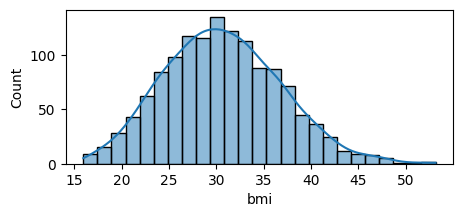

In [ ]:
# data type of bmi is numerical so we can replace with either mean or median
# check the distribution of data
plt.figure(figsize=(5,2))
sns.histplot(data , x='bmi',kde=True)
plt.show()

In [ ]:
#  skewness : used to measure the distribution of data
# skew = [-0.5,0.5]--> normal distribution
# skew > 0.5 --> right skewed
# skew <-0.5 --> left skewed
data['bmi'].skew()

np.float64(0.2837569339077387)

In [ ]:
# Distribution of bmi is normal , hence replace with mean
data['bmi'].mean()

np.float64(30.664205992509366)

In [ ]:
data['bmi']=data['bmi'].fillna(data['bmi'].mean())

**Charges**

In [ ]:
data['charges'].dtypes

dtype('float64')

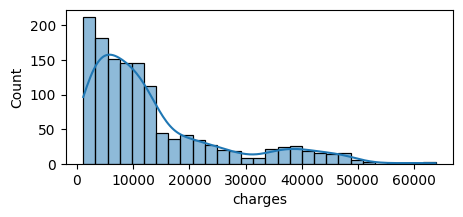

In [ ]:
# since data type is numerical we can replace with either mean or median
# check the distribution
plt.figure(figsize=(5,2))
sns.histplot(data , x='charges',kde=True)
plt.show()

In [ ]:
# check skew
data['charges'].skew()
# right skew as skewness is greater than 0.5

np.float64(1.5132403708665176)

In [ ]:
# since distribution of charges is right skewed , we place with median
data['charges'].median()

9401.1755

In [ ]:
data['charges'] = data['charges'].fillna(data['charges'].median())

In [ ]:
data.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


# **Exploratory Data Analysis**
Process of analysing data by performing different visualizations and interpreting the results.


**Univariate Analysis**

Analysing single variable
- histogram
- count plot
- pie chart
- box plot

**Check the distibution of age**

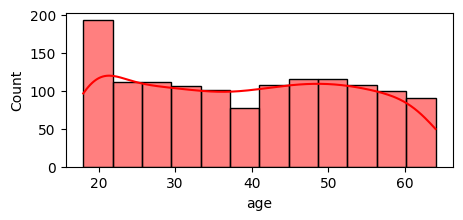

In [ ]:
# Histogram used to check distribution of data which requires 1 numerical column
plt.figure(figsize=(5,2))
sns.histplot(data,x='age',kde=True,color='red')
plt.show()

**Insights**
1. Distribution of age is uniform as it focus on different age groups.
2. The age distribution is spread across a range of 18 to 64.
3. Frequency of applicants are bit higher around ealry 20's
4. There are no extreme values

**Check the distibution of bmi**

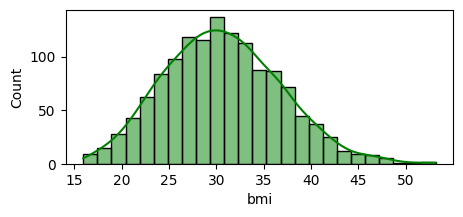

In [ ]:
plt.figure(figsize=(5,2))
sns.histplot(data,x='bmi',kde=True,color='green')
plt.show()

**Insights**
1. Distribution of bmi is normal.
2. Peak of distribution is around 30.
3. The most distribution is within 25 to 38.
4. No outliers are seen

**Check the distibution of charges**

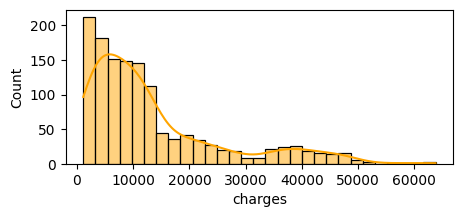

In [ ]:
plt.figure(figsize=(5,2))
sns.histplot(data,x='charges',kde=True,color='orange')
plt.show()

**Insights**
1. Distribution of charges is righ skew , indicates that there are few extreme charges towards right.
2. Most indivisuals have insurance charge less than 15000.
3. Very few people have insurance charges above 30000.
4. Outliers are seen towards right

**Count of Gender**

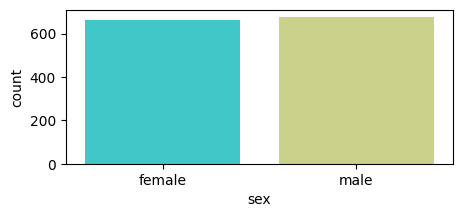

In [ ]:
# count plot used to visualise the count of categories
plt.figure(figsize=(5,2))
sns.countplot(data,x='sex',palette='rainbow',hue='sex')
plt.show()

**Insights**

We have equal information related to Male and Female

**Count of Smoker**

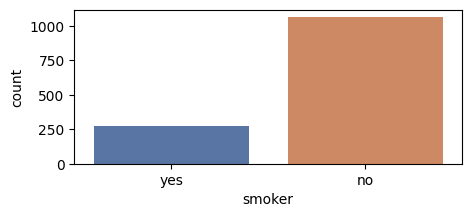

In [ ]:
plt.figure(figsize=(5,2))
sns.countplot(data,x='smoker',palette='deep',hue='smoker')
plt.show()

**Insights**

Maximum customers are non smokers and very few are smokers

**Count of Region**

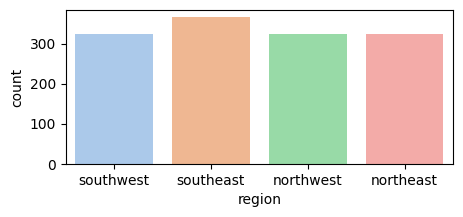

In [ ]:
plt.figure(figsize=(5,2))
sns.countplot(data,x='region',palette='pastel',hue='region')
plt.show()

**Insights**

Maximum customers are from Southeast and almost same number of customers we have from rest of regions.

palette='deep'
palette='muted'
palette='bright'
palette='pastel'
palette='dark'
palette='colorblind'

palette='Set1'
palette='Set2'
palette='Set3'
palette='Paired'
palette='Accent'
palette='rainbow'

palette='viridis'
palette='plasma'
palette='inferno'
palette='magma'
palette='coolwarm'
palette='Spectral'

**What percentage of applicants are smokers and non smokers**

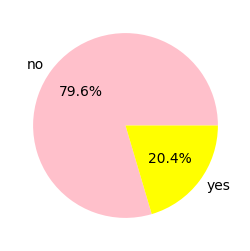

In [ ]:
plt.figure(figsize=(3,3))
data['smoker'].value_counts().plot(kind='pie',autopct='%1.1f%%',colors=['pink','yellow'])
plt.ylabel('')
plt.show()


**Insights**

1. Almost 80% of the customers are non smokers.
2. 20% of them are smokers

**What percentage of male and female applicants**

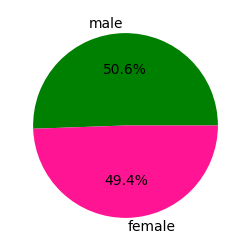

In [ ]:
plt.figure(figsize=(3,3))
data['sex'].value_counts().plot(kind='pie',autopct='%1.1f%%',colors=['green','deeppink'])
plt.ylabel('')
plt.show()

**Insights**

Almost equal amount of male and female customers.

**What percentage of people belong to different region**

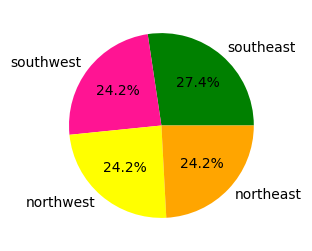

In [ ]:
plt.figure(figsize=(3,3))
data['region'].value_counts().plot(kind='pie',autopct='%1.1f%%',
                                   colors=['green','deeppink','yellow','orange'])
plt.ylabel('')
plt.show()

**Check outliers in age , bmi , charges**

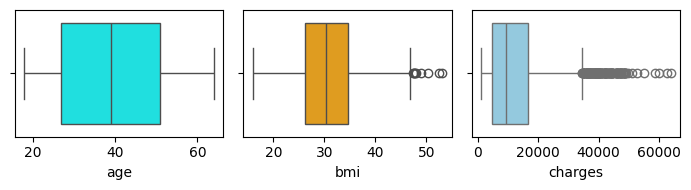

In [ ]:
# Box plot to check outliers
fig,ax = plt.subplots(1,3,figsize=(7,2))
sns.boxplot(data,x='age',ax=ax[0],color='cyan')
sns.boxplot(data,x='bmi',ax=ax[1],color='orange')
sns.boxplot(data,x='charges',ax=ax[2],color='skyblue')
plt.tight_layout()

**Insights**

- Age doesn't have any outliers.
- Outliers are seen in bmi and charges towards right side.

**Bivariate Analysis**

Analysing two variables
- bar chart
- line chart
- box plot
- scatter plot

**Find the relationship between age and charges**

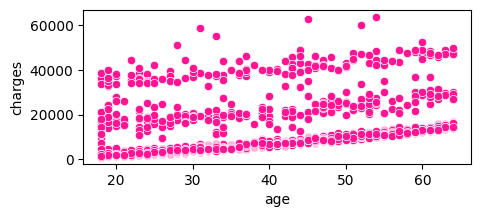

In [ ]:
# Scatter plot : Used to find relationship between 2 numerical variables
plt.figure(figsize=(5,2))
sns.scatterplot(data,x='age',y='charges',color='deeppink')
plt.show()

**Insights**

- There is slight positive relationship between age and charges.
- As age increases charges increases and vice versa.

**Find the relationship between age and bmi**

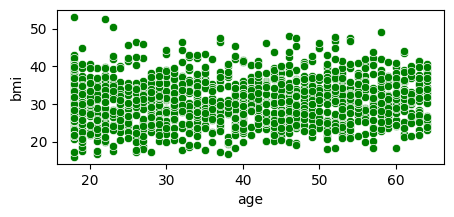

In [ ]:
plt.figure(figsize=(5,2))
sns.scatterplot(data,x='age',y='bmi',color='green')
plt.show()

**Insights**

There is no relationship between age and bmi.

**Find the relationship between bmi and charges and smoker**

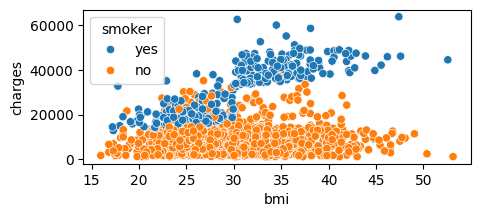

In [ ]:
plt.figure(figsize=(5,2))
sns.scatterplot(data,x='bmi',y='charges',hue='smoker')
plt.show()

**Insights**
- There is a exponential increase in charges as bmi increases for smokers.
- Not much variation seen between bmi and charges for non smokers.

**Check how charges vary with Gender**

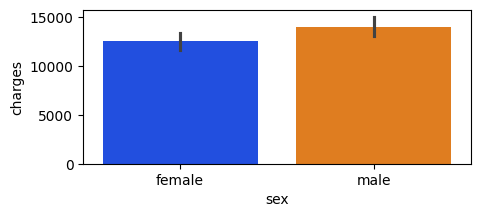

In [ ]:
plt.figure(figsize=(5,2))
sns.barplot(data,x='sex',y='charges',palette='bright',hue='sex')
plt.show()

**Insights**

- Insurance charges are high for male compared to female.

**Check how charges vary with smokers and non smokers**

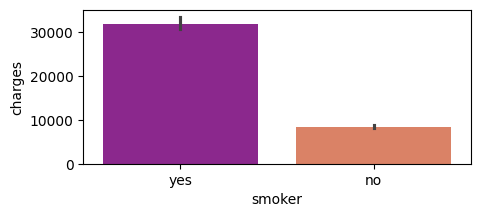

In [ ]:
plt.figure(figsize=(5,2))
sns.barplot(data,x='smoker',y='charges',hue='smoker',palette='plasma')
plt.show()

**Insights**

Insurance charges will be high for smokers compared to non smokers.

**Multivariate Analysis**

Analysing multiple variables
- pair plot
- heat map

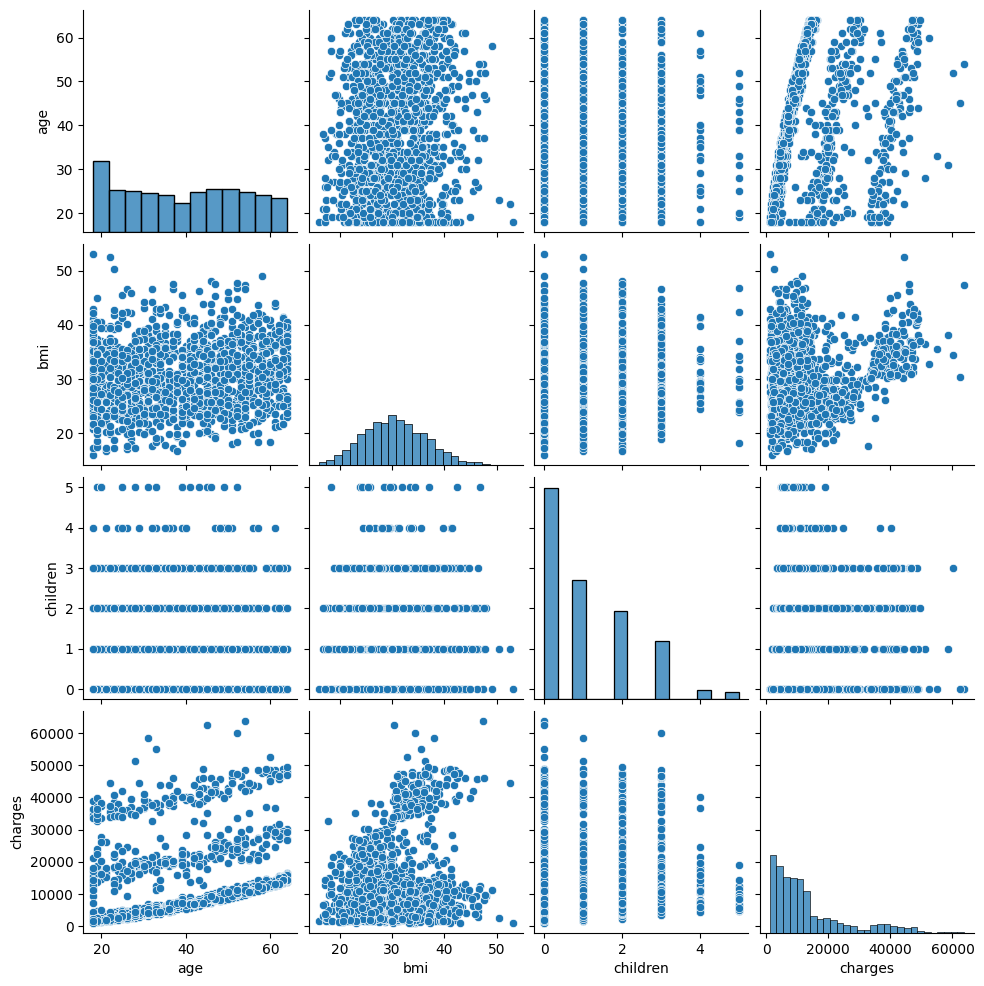

In [ ]:
# pairplot : scatter plot for all numerical columns
sns.pairplot(data)

In [ ]:
# heat map: visualise the correlation of numerical columns
# correlation : How two variables are related
num_data.corr()

,age,bmi,children,charges
age,1.000000,0.109527,0.042469,0.297990
bmi,0.109527,1.000000,0.012658,0.197808
children,0.042469,0.012658,1.000000,0.066767
charges,0.297990,0.197808,0.066767,1.000000


<Axes: >

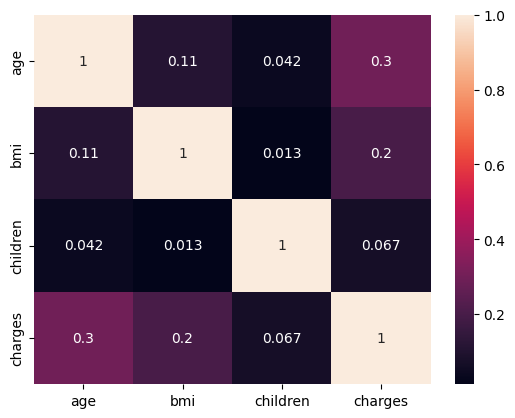

In [ ]:
sns.heatmap(num_data.corr(),annot=True)

# **Feature Engineering**

### **Handling Outliers**

Outliers are extreme values which are away from actual data.

Age : [20,22,23,24,26,28,100,200]

100 and 200 are outliers

**How to identify the direction of outliers**

- **box plot**
- scatter plot
- histogram

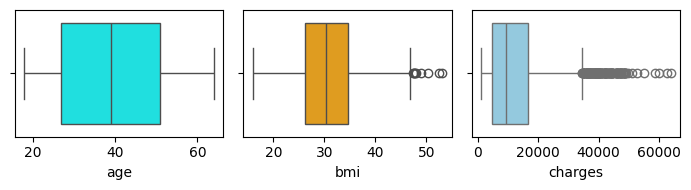

In [ ]:
# Box plot to check outliers
fig,ax = plt.subplots(1,3,figsize=(7,2))
sns.boxplot(data,x='age',ax=ax[0],color='cyan')
sns.boxplot(data,x='bmi',ax=ax[1],color='orange')
sns.boxplot(data,x='charges',ax=ax[2],color='skyblue')
plt.tight_layout()

There are outliers in **bmi** and **charges**.

**How to find outliers**

We have two methods based on data distribution of data.
- IQR : Use this when data distribution is skewed.
- 3 sigma rule : Use this when data distribution is normal.



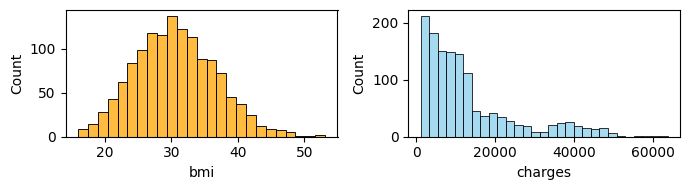

In [ ]:
fig,ax = plt.subplots(1,2,figsize=(7,2))
sns.histplot(data,x='bmi',ax=ax[0],color='orange')
sns.histplot(data,x='charges',ax=ax[1],color='skyblue')
plt.tight_layout()

**Bmi** distribution is **normal** , hence we use 3-sigma rule.

**3-sigma rule**

1. find mean
2. find standard deviation
3. find lower_limit = mean - 3 * std
4. find upper_limit = mean + 3 * std
5. Outliers are the values which are less than lower_limit or greater than upper_limit

In [ ]:
# bmi
mean_val = data['bmi'].mean()
std_val = data['bmi'].std()
lower_limit = mean_val - 3*std_val
upper_limit = mean_val + 3*std_val

In [ ]:
# find all values less than lower limit
data[data['bmi']<lower_limit]

,age,sex,bmi,children,smoker,region,charges


In [ ]:
# find all values greater than upper limit
data[data['bmi']>upper_limit]

,age,sex,bmi,children,smoker,region,charges
116,58,male,49.06,0,no,southeast,11381.3254
847,23,male,50.38,1,no,southeast,2438.0552
1047,22,male,52.58,1,yes,southeast,44501.3982
1317,18,male,53.13,0,no,southeast,1163.4627


Outliers should be replaced with either mean or median based on method only if % of outliers is less than 5%.

In [ ]:
len(data[(data['bmi']<lower_limit)|(data['bmi']>upper_limit)])/len(data)*100

0.2991772625280479

In [ ]:
# will replace with mean as bmi distribution is normal
data.loc[(data['bmi']<lower_limit)|(data['bmi']>upper_limit),'bmi']=data['bmi'].mean()

In [ ]:
len(data[(data['bmi']<lower_limit)|(data['bmi']>upper_limit)])/len(data)*100

0.0

**charges** distribution is **right skewed** , hence we use IQR method.

IQR -> Inter quartile range

1. Find Q1
2. Find Q3
3. IQR : Q3-Q1
4. lower_limit = Q1 - 1.5 * IQR
5. upper_limit = Q3 + 1.5 * IQR
6. Outliers are values less than lower_limit or greater than upper_limit.

In [ ]:
Q1 = data['charges'].quantile(0.25)
Q3 = data['charges'].quantile(0.75)
IQR = Q3-Q1
lower_limit= Q1- 1.5*IQR
upper_limit = Q3 + 1.5*IQR

In [ ]:
# find all values greater than upper_limit
data[data['charges']>upper_limit]

,age,sex,bmi,children,smoker,region,charges
14,27,male,42.130,0,yes,southeast,39611.75770
19,30,male,35.300,0,yes,southwest,36837.46700
23,34,female,31.920,1,yes,northeast,37701.87680
29,31,male,36.300,2,no,southwest,38711.00000
30,22,male,35.600,0,yes,southwest,35585.57600
...,...,...,...,...,...,...,...
1300,45,male,30.360,0,yes,southeast,62592.87309
1301,62,male,30.875,3,yes,northwest,46718.16325
1303,43,male,27.800,0,yes,southwest,37829.72420
1313,19,female,34.700,2,yes,southwest,36397.57600


In [ ]:
# find all values less than lower_limit
data[data['charges']<lower_limit]

,age,sex,bmi,children,smoker,region,charges


In [ ]:
# find % of outliers
len(data[(data['charges']>upper_limit)|(data['charges']<lower_limit)])/len(data)*100

10.396409872849663

Since % of outliers in charges is more than 5% we leave them as it is. There can be higher charges for few cases.

### **Encoding**

Process of converting text to a number

**why**

Machines do not understand text hence need to convert into numbers

### **Label Encoder**

It assigns numbers starting from 0 to each category based on alphabetical order.

**Eg:1**

Yes - 1

No - 0

**Eg:2**

Red - 2

green - 1

Blue - 0


**Limitations**

UG - 2

PG - 0

PHD - 1

Model thinks UG has high importance as its value is 2 compared to other two. But in reality high importance should be given for PHD. Hence **Label Encoder** is not good when order matters.


Male - 1

Female - 0

Model thinks male is dominant than female. But in reality we should give equal importance. Hence **Label Encoder fails when equal importance should be given**

**When to use**

1 . Yes-1 , No-0

2. True -1 , False-0

3. Positive - 1 , Negative-0

In [ ]:
# Since smoker has values yes / No will use Label Encoder
# sklearn: scikit learn
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['Smoker']= le.fit_transform(data['smoker'])

### **One hot Encoding**

- This converts text to binary values either 0 or 1.
- It creates seperate columns for each category.
- It should be used when equal priority should be given.

**Limitations**

If categories are more , it increases number of columns in data

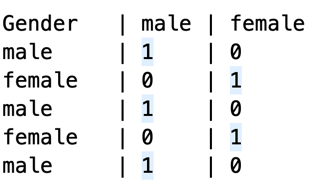

In [ ]:
data =pd.get_dummies(data,columns=['sex'],dtype='int64')

### **Ordinal Encoding**


**Ordinal Encoding** converts categorical values into numerical values based on their order or ranking.

Used when categories have a meaningful order.

UG - 0

PG - 1

PHD - 2

In [ ]:
#first method: example of OrdinalEncoder
df = pd.DataFrame({
'Education':['PHD','UG','PG','UG']
})
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder(categories=[['UG','PG','PHD']])
df[['education']]=oe.fit_transform(df[['Education']])


In [ ]:
# second method manually assign values using map
df['edu']= df['Education'].map({'UG':0,'PG':1,'PHD':2})

In [ ]:
df

,Education,education,edu
0,PHD,2.0,2
1,UG,0.0,0
2,PG,1.0,1
3,UG,0.0,0


In [ ]:
data

,age,bmi,children,smoker,region,charges,Smoker,sex_female,sex_male
0,19,27.900,0,yes,southwest,16884.92400,1,1,0
1,18,33.770,1,no,southeast,1725.55230,0,0,1
2,28,33.000,3,no,southeast,4449.46200,0,0,1
3,33,22.705,0,no,northwest,21984.47061,0,0,1
4,32,28.880,0,no,northwest,3866.85520,0,0,1
...,...,...,...,...,...,...,...,...,...
1333,50,30.970,3,no,northwest,10600.54830,0,0,1
1334,18,31.920,0,no,northeast,2205.98080,0,1,0
1335,18,36.850,0,no,southeast,1629.83350,0,1,0
1336,21,25.800,0,no,southwest,2007.94500,0,1,0


### **Target Encoding**

We assign numerical values to the categories based on its importance with target.

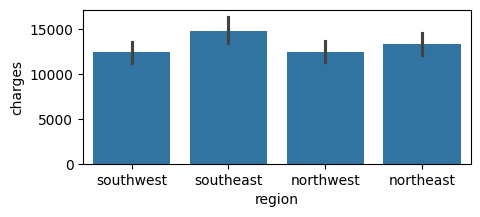

In [ ]:
# region
plt.figure(figsize=(5,2))
sns.barplot(data,x='region',y='charges')
plt.show()

In [ ]:
data['Region']= data['region'].map({'northwest':0,'southwest':1,'northeast':2,'southeast':3})

In [ ]:
# drop columns
data.drop(columns=['smoker','region'],inplace=True)
# data[['age',	'bmi',	'children',	'charges',	'Smoker',	'sex_female',	'sex_male','Region]]

In [ ]:
data

,age,bmi,children,charges,Smoker,sex_female,sex_male,Region
0,19,27.900,0,16884.92400,1,1,0,1
1,18,33.770,1,1725.55230,0,0,1,3
2,28,33.000,3,4449.46200,0,0,1,3
3,33,22.705,0,21984.47061,0,0,1,0
4,32,28.880,0,3866.85520,0,0,1,0
...,...,...,...,...,...,...,...,...
1333,50,30.970,3,10600.54830,0,0,1,0
1334,18,31.920,0,2205.98080,0,1,0,2
1335,18,36.850,0,1629.83350,0,1,0,3
1336,21,25.800,0,2007.94500,0,1,0,1


### **Scaling**

Feature Scaling is the process of bringing all numerical features to a similar range or scale.

It helps ML algorithms perform better and faster.

**Why Scaling??**

**Age** -- > small values(20,30,40)

**Salary** --> bigger values(25000,50000,80000)

Algorithms gives more importance to larger values in salary. To overcome this we use scaling.


**Types of Scaling**

- Standard scaler
- Minmax scaler

**Standard Scaler(Standardization)**

It transforms all the values to a same scale where mean will be 0 and standard deviation will be 1.

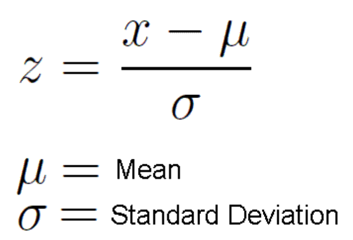

In [ ]:
df1 = data.copy() # create copy of data

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
df1[['age','bmi']]= sc.fit_transform(df1[['age','bmi']])

In [ ]:
df1

,age,bmi,children,charges,Smoker,sex_female,sex_male,Region
0,-1.440418,-0.451171,0,16884.92400,1,1,0,1
1,-1.511647,0.528799,1,1725.55230,0,0,1,3
2,-0.799350,0.400251,3,4449.46200,0,0,1,3
3,-0.443201,-1.318452,0,21984.47061,0,0,1,0
4,-0.514431,-0.287564,0,3866.85520,0,0,1,0
...,...,...,...,...,...,...,...,...
1333,0.767704,0.061351,3,10600.54830,0,0,1,0
1334,-1.511647,0.219950,0,2205.98080,0,1,0,2
1335,-1.511647,1.042990,0,1629.83350,0,1,0,3
1336,-1.297958,-0.801756,0,2007.94500,0,1,0,1


**Min Max Scaler(Normalization)**

Min-Max Scaling is a normalization technique that scales data into a range of 0 to 1.

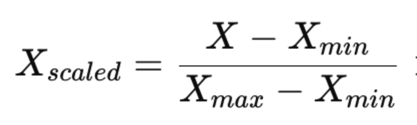

In [ ]:
from sklearn.preprocessing import MinMaxScaler
sc = MinMaxScaler()
data[['age','bmi']]= sc.fit_transform(data[['age','bmi']])

In [ ]:
data

,age,bmi,children,charges,Smoker,sex_female,sex_male,Region
0,0.021739,0.371847,0,16884.92400,1,1,0,1
1,0.000000,0.554656,1,1725.55230,0,0,1,3
2,0.217391,0.530676,3,4449.46200,0,0,1,3
3,0.326087,0.210059,0,21984.47061,0,0,1,0
4,0.304348,0.402367,0,3866.85520,0,0,1,0
...,...,...,...,...,...,...,...,...
1333,0.695652,0.467456,3,10600.54830,0,0,1,0
1334,0.000000,0.497041,0,2205.98080,0,1,0,2
1335,0.000000,0.650576,0,1629.83350,0,1,0,3
1336,0.065217,0.306447,0,2007.94500,0,1,0,1


#**Feature Transformation**

Converts non normal distribution of target column into normal

**When to Use Feature Transformation**

Use when:

- Target Data is skewed
- Distribution of target is non-normal


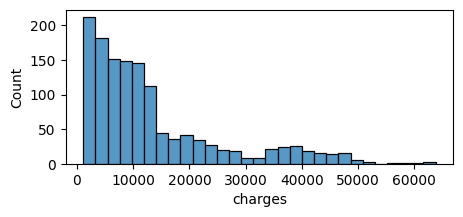

In [ ]:
plt.figure(figsize=(5,2))
sns.histplot(data,x='charges')
plt.show()

**log transformation**

In [ ]:
data['charges']=np.log(data['charges'])

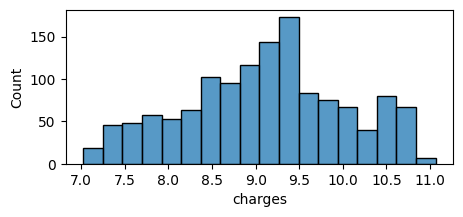

In [ ]:
plt.figure(figsize=(5,2))
sns.histplot(data,x='charges')
plt.show()

**Note**

1. Outliers done on continuous columns
2. Scaling done  only on input continuous columns.
3. Log transformation applied only in regression on a target column.
4. Encoding done on categorical columns

In [ ]:
data

,age,bmi,children,charges,Smoker,sex_female,sex_male,Region
0,0.021739,0.371847,0,9.734176,1,1,0,1
1,0.000000,0.554656,1,7.453302,0,0,1,3
2,0.217391,0.530676,3,8.400538,0,0,1,3
3,0.326087,0.210059,0,9.998092,0,0,1,0
4,0.304348,0.402367,0,8.260197,0,0,1,0
...,...,...,...,...,...,...,...,...
1333,0.695652,0.467456,3,9.268661,0,0,1,0
1334,0.000000,0.497041,0,7.698927,0,1,0,2
1335,0.000000,0.650576,0,7.396233,0,1,0,3
1336,0.065217,0.306447,0,7.604867,0,1,0,1


### **Feature Selection**

1. Drop columns which are not important(id,unwanted columns)
2. Drop constant columns
3. Create new columns
4. Select and drop columns based on correlation


In [ ]:
df = data[['age',	'bmi'	,'children',	'charges']]
df.corr()

,age,bmi,children,charges
age,1.000000,0.118775,0.041536,0.524724
bmi,0.118775,1.000000,0.017923,0.138379
children,0.041536,0.017923,1.000000,0.158151
charges,0.524724,0.138379,0.158151,1.000000


<Axes: >

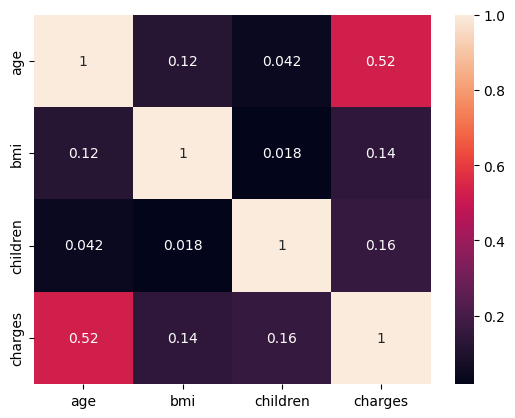

In [ ]:
sns.heatmap(df.corr(),annot=True)
# Include columns which has high correlation with target
# If corr with target is very less we can drop such columns
# If corr between any two input variables is high , drop one of them.(eg: area,sqft you can drop one)

In [ ]:
data

,age,bmi,children,charges,Smoker,sex_female,sex_male,Region
0,0.021739,0.371847,0,9.734176,1,1,0,1
1,0.000000,0.554656,1,7.453302,0,0,1,3
2,0.217391,0.530676,3,8.400538,0,0,1,3
3,0.326087,0.210059,0,9.998092,0,0,1,0
4,0.304348,0.402367,0,8.260197,0,0,1,0
...,...,...,...,...,...,...,...,...
1333,0.695652,0.467456,3,9.268661,0,0,1,0
1334,0.000000,0.497041,0,7.698927,0,1,0,2
1335,0.000000,0.650576,0,7.396233,0,1,0,3
1336,0.065217,0.306447,0,7.604867,0,1,0,1


# **Split data for x and y**

In [ ]:
x = data.drop(columns='charges')
y = data['charges']

# **Split data for Training and Testing**

In [ ]:
# 70:30
# 80: 20
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)
# random_state=controls the randomness

In [ ]:
x_train.shape

(1069, 7)

# **Linear Regression Model**

In [ ]:
from sklearn.linear_model import LinearRegression
linear_model = LinearRegression()
# train model:x_train,y_train
linear_model.fit(x_train,y_train)
# test the model
y_pred = linear_model.predict(x_test)

In [ ]:
results = pd.DataFrame({'actual_y':y_test,'predict_value':y_pred})
results

,actual_y,predict_value
900,9.069797,8.882249
1064,8.649776,8.710501
1256,9.344586,9.495605
298,10.564792,10.260942
237,8.403622,8.645264
...,...,...
534,9.534676,9.589695
542,9.538723,9.572765
760,8.275315,8.374459
1284,10.766459,11.090162


In [ ]:
# find slope
linear_model.coef_

array([ 1.55286056,  0.38049708,  0.09717217,  1.53049381,  0.03317997,
       -0.03317997, -0.0118035 ])

In [ ]:
# find c
linear_model.intercept_

np.float64(7.8148675239512535)

# **Evaluate the model**
- MSE
- MAE
- RMSE
- MAPE
- r2
- adjusted

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,mean_absolute_percentage_error,r2_score

In [ ]:
# mean absolute error
mean_absolute_error(y_test,y_pred)

0.27488511085864803

In [ ]:
# mean squared error
mean_squared_error(y_test,y_pred)

0.17950239607239524

In [ ]:
# root mean squared error
np.sqrt(mean_squared_error(y_test,y_pred))

np.float64(0.42367723100539073)

In [ ]:
# mean absolute percentage error
mean_absolute_percentage_error(y_test,y_pred)

0.030459255052072153

In [ ]:
# r2 score
r2 = r2_score(y_test,y_pred)
r2

0.8066082171273394

80% good model /better model.

80% of the predictions made by the model are correct.

In [ ]:
# adjusted r2 score
n = x_test.shape[0] # number of rows
p = x_test.shape[1] # number of input columns

adj = 1 - (1-r2)*(n-1)/(n-p-1)
adj

0.8014015152807679

# **Regularization**

Regularization is a concept in machine learning used to prevent **overfitting** when a model learns the training data too well (including noise) and performs poorly on new data.

Regularization adds a **penalty to a model’s** complexity so it doesn’t become overly complicated.

### **L1 Regularization** (Lasso Regression)

L1 Regularization adds the absolute values of coefficients as a penalty term to the loss function.

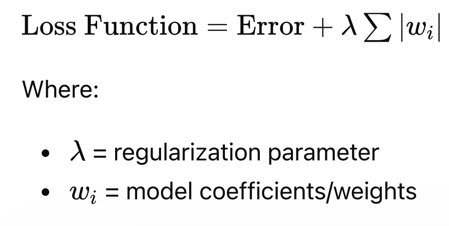

**What it does**
- Reduces coefficient values
- Some coefficients become exactly 0
- Removes less important features automatically

**Why use L1?**

- Feature selection
- Reducing unnecessary features

**Eg:**

Suppose predicting house price using:

- Area
- Bedrooms
- Age
- Color of house

If “Color” is not useful, L1 may make its coefficient = 0.

**Advantages**
- Performs feature selection
- Reduces overfitting
- Creates simple models

**Disadvantages**
- Can remove useful features if penalty is too high
- Less stable when features are highly correlated

In [ ]:
from sklearn.linear_model import Lasso
lasso_model = Lasso(alpha=0.01)
lasso_model.fit(x_train,y_train)
y_pred = lasso_model.predict(x_test)
# alpha(lambda) is regularization parameter which controls the strength of regularization


In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.18956805095119414
r2 0.7957637103943667


### **L2 Regularization** (Ridge Regression)

L2 Regularization adds the square of coefficients as a penalty term to the loss function.

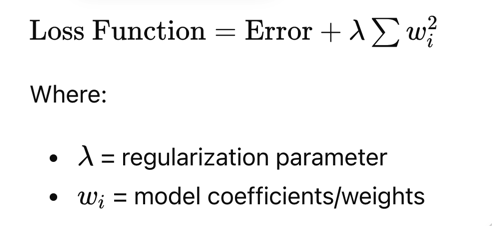

**What it does**
- Shrinks coefficient values toward zero
- Does not make coefficients exactly zero
- Keeps all features in the model

**Why use L2?**
- Reducing overfitting
- Handling multicollinearity
- Improving model generalization

**Eg:**

Suppose predicting salary using:

- Experience
- Skills
- Education
- Certifications

L2 reduces the influence of less important features but keeps them in the model.

**Advantages**
- Reduces overfitting
- Works well when all features are important
- Handles correlated features better

**Disadvantages**
- Does not perform feature selection
- Model may still contain unnecessary features

In [ ]:
from sklearn.linear_model import Ridge
ridge_model = Ridge(alpha=0.01)
ridge_model.fit(x_train,y_train)
y_pred = ridge_model.predict(x_test)

In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.17950827281653597
r2 0.8066018856573884


In [ ]:
ridge_model.coef_

array([ 1.55270523,  0.38041553,  0.09717461,  1.53039696,  0.03317699,
       -0.03317699, -0.01179852])

In [ ]:
lasso_model.coef_

array([ 1.4688841 ,  0.08338733,  0.09255609,  1.45490395,  0.01947096,
       -0.        , -0.        ])

###**Elastic Net Regularization**

Elastic Net combines both:

- L1 Regularization (Lasso)
- L2 Regularization (Ridge)

It uses both penalties together.

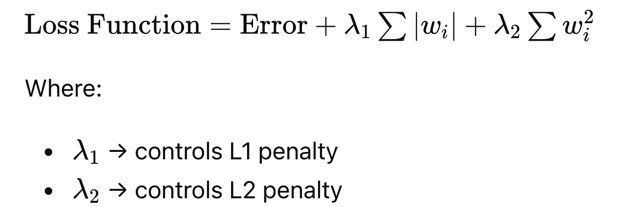

**What it does**
- Shrinks coefficients
- Some coefficients become zero
- Keeps important correlated features

**Why use Elastic Net?**

- Dataset has many features
- Features are highly correlated
- Need both feature selection and regularization

**Eg:**

Suppose predicting customer churn using:

- Age
- Salary
- Usage time
- App activity
- Purchase history

Some features may be removed, while important correlated features are retained.

**Advantages**
- Combines benefits of L1 and L2
- Performs feature selection
- Handles multicollinearity better
- Works well for high-dimensional data

**Disadvantages**
- More complex than Ridge and Lasso
- Requires tuning two parameters

In [ ]:
from sklearn.linear_model import ElasticNet
et_model = ElasticNet(alpha=0.01,l1_ratio=0.5)
et_model.fit(x_train,y_train)
y_pred=et_model.predict(x_test)
# l1_ratio: controls balance between L1 and L2
# 0--> L2
# 1--> L1
# 0.5 --> mix of both

# alpha : controls regularization

In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.18890370646286156
r2 0.7964794599768317


In [ ]:
et_model.coef_

array([ 1.43283663e+00,  2.09652910e-01,  9.61279165e-02,  1.44344474e+00,
        2.36104667e-02, -1.67680435e-02, -6.11802232e-04])

# KNN Regressor

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
model = KNeighborsRegressor(n_neighbors=5)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('MAE',mean_absolute_error(y_test,y_pred))
print('RMSE',np.sqrt(mean_squared_error(y_test,y_pred)))
print('MAPE',mean_absolute_percentage_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.19879179172665318
MAE 0.298437920614901
RMSE 0.44586073131265236
MAPE 0.03245695938012153
r2 0.7858262626925441


# Decision Tree Regressor

In [ ]:
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor(criterion='absolute_error',splitter='best',max_depth=5,
                              max_features='sqrt',min_samples_split=5,
                              min_samples_leaf=4)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)
# criterion : absolute_error,squared_error,friedman_mse

In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('MAE',mean_absolute_error(y_test,y_pred))
print('RMSE',np.sqrt(mean_squared_error(y_test,y_pred)))
print('MAPE',mean_absolute_percentage_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.6906126976315414
MAE 0.6180498541000836
RMSE 0.8310311050926682
MAPE 0.07006025554923956
r2 0.2559496486297833


# Random Forest Regressor

In [ ]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(criterion='squared_error',max_depth=15,
                              max_features='sqrt',min_samples_split=3,
                              min_samples_leaf=5,n_estimators=30,bootstrap=True)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('MAE',mean_absolute_error(y_test,y_pred))
print('RMSE',np.sqrt(mean_squared_error(y_test,y_pred)))
print('MAPE',mean_absolute_percentage_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.15298407929627184
MAE 0.2553203606523483
RMSE 0.3911317927454528
MAPE 0.0282101371291739
r2 0.8351784461177543


# Grid Search

In [ ]:
from sklearn.model_selection import GridSearchCV
model = DecisionTreeRegressor()
parameters = {'criterion':['squared_error','absolute_error'],
              'max_depth':[5,10,15,20,25],'max_features':['sqrt','log2'],
              'min_samples_split':[2,3,4,5,6,7,8],'min_samples_leaf':[2,3,4,5,6,7,8],
              'splitter':['best','random']}
grid = GridSearchCV(estimator=model,param_grid=parameters,cv=5)
grid.fit(x_train,y_train)

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(),
             param_grid={'criterion': ['squared_error', 'absolute_error'],
                         'max_depth': [5, 10, 15, 20, 25],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [2, 3, 4, 5, 6, 7, 8],
                         'min_samples_split': [2, 3, 4, 5, 6, 7, 8],
                         'splitter': ['best', 'random']})

In [ ]:
print(grid.best_params_)

{'criterion': 'absolute_error', 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 6, 'min_samples_split': 8, 'splitter': 'best'}


In [ ]:
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor(criterion='absolute_error',splitter='best',max_depth=20,
                              max_features='sqrt',min_samples_split=6,
                              min_samples_leaf=7)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('MAE',mean_absolute_error(y_test,y_pred))
print('RMSE',np.sqrt(mean_squared_error(y_test,y_pred)))
print('MAPE',mean_absolute_percentage_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.2615932886081948
MAE 0.3162976533734791
RMSE 0.5114619131550215
MAPE 0.03573315441803904
r2 0.7181653639260739


# **Gradient Boosting Regressor**

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
model = GradientBoostingRegressor(criterion='friedman_mse',max_depth=3,
                              max_features=None,min_samples_split=4,
                              min_samples_leaf=3,n_estimators=10,loss='squared_error',
                                   learning_rate=0.5,subsample=1.0)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('MAE',mean_absolute_error(y_test,y_pred))
print('RMSE',np.sqrt(mean_squared_error(y_test,y_pred)))
print('MAPE',mean_absolute_percentage_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.12392888541658591
MAE 0.19768721345092108
RMSE 0.3520353468283915
MAPE 0.021835550483577024
r2 0.866481848573937


# XGBRegressor

In [ ]:
from xgboost import XGBRegressor
model = XGBRegressor(n_estimators=20,max_depth=3,learning_rate=0.5,gamma=0.02 ,
                      reg_alpha=0.01 , reg_lambda=0.1, colsample_bytree=0.7
                      ,subsample=0.8 ,n_jobs=-1)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('MAE',mean_absolute_error(y_test,y_pred))
print('RMSE',np.sqrt(mean_squared_error(y_test,y_pred)))
print('MAPE',mean_absolute_percentage_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.13060940333381194
MAE 0.2180464281785228
RMSE 0.3613992298467333
MAPE 0.024163051639584553
r2 0.8592844111090685


# Support Vector Regressor

In [ ]:
from sklearn.svm import SVR
model = SVR(kernel='poly',gamma=0.5 , C =10)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [ ]:
print('MSE',mean_squared_error(y_test,y_pred))
print('MAE',mean_absolute_error(y_test,y_pred))
print('RMSE',np.sqrt(mean_squared_error(y_test,y_pred)))
print('MAPE',mean_absolute_percentage_error(y_test,y_pred))
print('r2',r2_score(y_test,y_pred))

MSE 0.12340311780942542
MAE 0.16103511603024312
RMSE 0.35128779911836594
MAPE 0.01692089907595792
r2 0.8670482985888128


In [ ]:
import pickle
with open('svm.pkl','wb') as f:
  pickle.dump(model,f)